# Hypothesis Testing in Python: A Comprehensive Tutorial
# ECON 5105 
# Lesson 8: Hypothesis Testing

This interactive notebook provides a comprehensive introduction to hypothesis testing using real-world business scenarios. We'll cover the fundamental concepts, statistical theory, and practical applications using Python.

## Learning Objectives
- Understand the logic and framework of hypothesis testing
- Learn about Type I and Type II errors through simulation
- Master one-sample and two-sample t-tests
- Explore the relationship between confidence intervals and hypothesis tests
- Conduct statistical power analysis
- Apply concepts to real-world business scenarios

---

In [18]:
# ============================================================================
# ECON 5105: Hypothesis Testing - Interactive Python Tutorial
# Lesson 8: Fundamentals of Hypothesis Testing
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("=" * 80)
print("HYPOTHESIS TESTING IN PYTHON: A COMPREHENSIVE TUTORIAL")
print("=" * 80)
print()

HYPOTHESIS TESTING IN PYTHON: A COMPREHENSIVE TUTORIAL



In [19]:
# ============================================================================
# UTILITY FUNCTIONS FOR HYPOTHESIS TESTING
# ============================================================================

def one_sample_z_test_proportion(sample_prop, null_prop, n, alpha=0.05, alternative='two-sided'):
    """
    Perform one-sample z-test for proportions
    
    Parameters:
    -----------
    sample_prop : float
        Sample proportion
    null_prop : float
        Null hypothesis proportion
    n : int
        Sample size
    alpha : float
        Significance level (default 0.05)
    alternative : str
        Type of test: 'two-sided', 'greater', 'less'
    
    Returns:
    --------
    dict: Contains z_statistic, p_value, critical_values, decision, and summary
    """
    # Calculate standard error under null hypothesis
    se = np.sqrt(null_prop * (1 - null_prop) / n)
    
    # Calculate z-statistic
    z_stat = (sample_prop - null_prop) / se
    
    # Calculate p-value and critical values based on alternative
    if alternative == 'two-sided':
        p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
        z_crit = stats.norm.ppf(1 - alpha/2)
        critical_values = (-z_crit, z_crit)
        reject = abs(z_stat) > z_crit
    elif alternative == 'greater':
        p_value = 1 - stats.norm.cdf(z_stat)
        z_crit = stats.norm.ppf(1 - alpha)
        critical_values = z_crit
        reject = z_stat > z_crit
    elif alternative == 'less':
        p_value = stats.norm.cdf(z_stat)
        z_crit = stats.norm.ppf(alpha)
        critical_values = z_crit
        reject = z_stat < z_crit
    else:
        raise ValueError("alternative must be 'two-sided', 'greater', or 'less'")
    
    decision = "REJECT H₀" if reject else "FAIL TO REJECT H₀"
    
    return {
        'z_statistic': z_stat,
        'p_value': p_value,
        'critical_values': critical_values,
        'standard_error': se,
        'decision': decision,
        'reject_null': reject,
        'alternative': alternative,
        'alpha': alpha
    }

def one_sample_t_test(sample_mean, sample_std, n, null_mean, alpha=0.05, alternative='two-sided'):
    """
    Perform one-sample t-test
    
    Parameters:
    -----------
    sample_mean : float
        Sample mean
    sample_std : float
        Sample standard deviation
    n : int
        Sample size
    null_mean : float
        Null hypothesis mean
    alpha : float
        Significance level (default 0.05)
    alternative : str
        Type of test: 'two-sided', 'greater', 'less'
    
    Returns:
    --------
    dict: Contains t_statistic, p_value, critical_values, decision, and summary
    """
    # Calculate standard error
    se = sample_std / np.sqrt(n)
    
    # Calculate t-statistic
    t_stat = (sample_mean - null_mean) / se
    
    # Degrees of freedom
    df = n - 1
    
    # Calculate p-value and critical values based on alternative
    if alternative == 'two-sided':
        p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df))
        t_crit = stats.t.ppf(1 - alpha/2, df)
        critical_values = (-t_crit, t_crit)
        reject = abs(t_stat) > t_crit
    elif alternative == 'greater':
        p_value = 1 - stats.t.cdf(t_stat, df)
        t_crit = stats.t.ppf(1 - alpha, df)
        critical_values = t_crit
        reject = t_stat > t_crit
    elif alternative == 'less':
        p_value = stats.t.cdf(t_stat, df)
        t_crit = stats.t.ppf(alpha, df)
        critical_values = t_crit
        reject = t_stat < t_crit
    else:
        raise ValueError("alternative must be 'two-sided', 'greater', or 'less'")
    
    decision = "REJECT H₀" if reject else "FAIL TO REJECT H₀"
    
    return {
        't_statistic': t_stat,
        'p_value': p_value,
        'critical_values': critical_values,
        'standard_error': se,
        'degrees_of_freedom': df,
        'decision': decision,
        'reject_null': reject,
        'alternative': alternative,
        'alpha': alpha
    }

def two_sample_z_test_proportion(n1, x1, n2, x2, alpha=0.05, alternative='two-sided'):
    """
    Perform two-sample z-test for proportions
    
    Parameters:
    -----------
    n1, n2 : int
        Sample sizes for groups 1 and 2
    x1, x2 : int
        Number of successes in groups 1 and 2
    alpha : float
        Significance level (default 0.05)
    alternative : str
        Type of test: 'two-sided', 'greater', 'less'
    
    Returns:
    --------
    dict: Contains z_statistic, p_value, critical_values, decision, and summary
    """
    # Calculate sample proportions
    p1 = x1 / n1
    p2 = x2 / n2
    
    # Pooled proportion (under null hypothesis of no difference)
    p_pooled = (x1 + x2) / (n1 + n2)
    
    # Standard error under null hypothesis
    se = np.sqrt(p_pooled * (1 - p_pooled) * (1/n1 + 1/n2))
    
    # Calculate z-statistic
    z_stat = (p1 - p2) / se
    
    # Calculate p-value and critical values based on alternative
    if alternative == 'two-sided':
        p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
        z_crit = stats.norm.ppf(1 - alpha/2)
        critical_values = (-z_crit, z_crit)
        reject = abs(z_stat) > z_crit
    elif alternative == 'greater':
        p_value = 1 - stats.norm.cdf(z_stat)
        z_crit = stats.norm.ppf(1 - alpha)
        critical_values = z_crit
        reject = z_stat > z_crit
    elif alternative == 'less':
        p_value = stats.norm.cdf(z_stat)
        z_crit = stats.norm.ppf(alpha)
        critical_values = z_crit
        reject = z_stat < z_crit
    else:
        raise ValueError("alternative must be 'two-sided', 'greater', or 'less'")
    
    decision = "REJECT H₀" if reject else "FAIL TO REJECT H₀"
    
    return {
        'z_statistic': z_stat,
        'p_value': p_value,
        'critical_values': critical_values,
        'standard_error': se,
        'sample_props': (p1, p2),
        'pooled_prop': p_pooled,
        'decision': decision,
        'reject_null': reject,
        'alternative': alternative,
        'alpha': alpha
    }

def print_test_results(test_result, test_name="Statistical Test"):
    """
    Print formatted results from hypothesis test functions
    """
    print(f"\n{test_name} Results:")
    print("-" * 60)
    
    if 't_statistic' in test_result:
        print(f"t-statistic: {test_result['t_statistic']:.4f}")
        print(f"Degrees of freedom: {test_result['degrees_of_freedom']}")
    else:
        print(f"z-statistic: {test_result['z_statistic']:.4f}")
    
    print(f"P-value: {test_result['p_value']:.6f}")
    print(f"Critical value(s): {test_result['critical_values']}")
    print(f"Decision: {test_result['decision']}")
    print(f"Significant at α = {test_result['alpha']}: {'Yes' if test_result['reject_null'] else 'No'}")

print("Utility functions for hypothesis testing loaded successfully!")

Utility functions for hypothesis testing loaded successfully!


---

## Part 1: Introduction - The Logic of Hypothesis Testing

### Business Scenario: Website Click-Through Rates

In this section, we'll explore hypothesis testing using a realistic AB testing scenario:

**Scenario:** You're a data scientist at an e-commerce company. Your current website has an average click-through rate (CTR) of 3.2%. You've designed a new landing page and want to test if it improves the CTR.

- **Null Hypothesis (H₀):** μ = 0.032 (3.2% - no improvement)
- **Alternative Hypothesis (H₁):** μ > 0.032 (improvement in CTR)

Let's generate sample data and explore the basics of hypothesis testing.

In [20]:
# ============================================================================
# PART 1: INTRODUCTION - THE LOGIC OF HYPOTHESIS TESTING
# ============================================================================

print("\n" + "=" * 80)
print("PART 1: INTRODUCTION - THE LOGIC OF HYPOTHESIS TESTING")
print("=" * 80)

print("""
Business Scenario: Website Click-Through Rates
----------------------------------------------
Current website CTR: 3.2%
New landing page tested with 1000 visitors
Question: Does the new design improve click-through rates?

Hypotheses:
H₀: μ = 0.032 (3.2% - no improvement)
H₁: μ > 0.032 (improvement in CTR)
""")

# Simulate website visitor data - binary outcomes (click/no click)
np.random.seed(42)
n = 1000  # Number of visitors
true_ctr = 0.038  # True CTR (unknown to us in practice) - 3.8%
baseline_ctr = 0.032  # Current website CTR - 3.2%

# Generate binary outcomes (1 = click, 0 = no click)
clicks = np.random.binomial(1, true_ctr, n)
sample_ctr = np.mean(clicks)
sample_std = np.std(clicks, ddof=1)

print(f"Sample Statistics:")
print(f"  Sample size (n): {n}")
print(f"  Sample CTR: {sample_ctr:.4f} ({sample_ctr*100:.2f}%)")
print(f"  Number of clicks: {np.sum(clicks)}")
print(f"  Sample std: {sample_std:.4f}")
print()


PART 1: INTRODUCTION - THE LOGIC OF HYPOTHESIS TESTING

Business Scenario: Website Click-Through Rates
----------------------------------------------
Current website CTR: 3.2%
New landing page tested with 1000 visitors
Question: Does the new design improve click-through rates?

Hypotheses:
H₀: μ = 0.032 (3.2% - no improvement)
H₁: μ > 0.032 (improvement in CTR)

Sample Statistics:
  Sample size (n): 1000
  Sample CTR: 0.0360 (3.60%)
  Number of clicks: 36
  Sample std: 0.1864



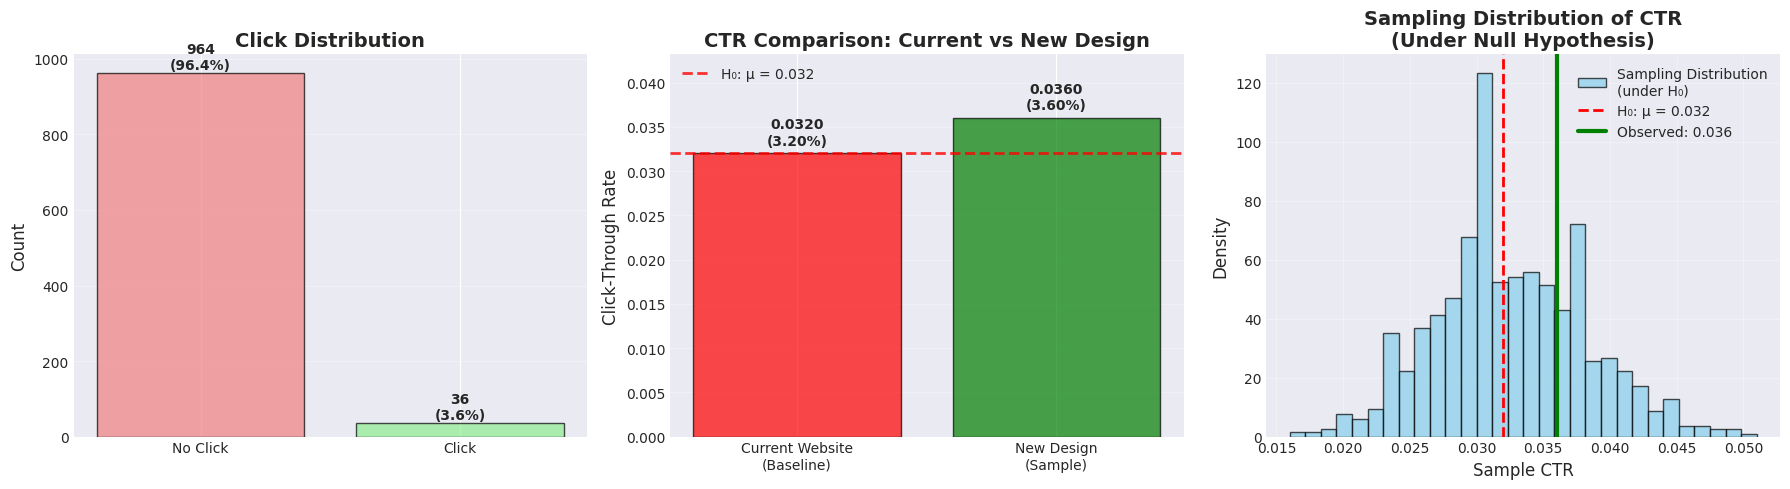

Key Observations:
• The sample CTR (0.0360) is higher than the baseline (0.0320)
• But is this difference statistically significant or just due to random chance?
• We need hypothesis testing to make this determination!


In [21]:
# Visualize the click-through data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bar plot of click vs no-click
click_counts = [n - np.sum(clicks), np.sum(clicks)]
labels = ['No Click', 'Click']
colors = ['lightcoral', 'lightgreen']

axes[0].bar(labels, click_counts, color=colors, edgecolor='black', alpha=0.7)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_title('Click Distribution', fontsize=14, fontweight='bold')
for i, v in enumerate(click_counts):
    axes[0].text(i, v + 10, f'{v}\n({v/n*100:.1f}%)', ha='center', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Comparison bar plot
ctrs = [baseline_ctr, sample_ctr]
ctr_labels = ['Current Website\n(Baseline)', 'New Design\n(Sample)']
colors_ctr = ['red', 'green']

bars = axes[1].bar(ctr_labels, ctrs, color=colors_ctr, alpha=0.7, edgecolor='black')
axes[1].axhline(baseline_ctr, color='red', linestyle='--', linewidth=2, alpha=0.8, label=f'H₀: μ = {baseline_ctr:.3f}')
axes[1].set_ylabel('Click-Through Rate', fontsize=12)
axes[1].set_title('CTR Comparison: Current vs New Design', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, max(ctrs) * 1.2)
for i, v in enumerate(ctrs):
    axes[1].text(i, v + 0.001, f'{v:.4f}\n({v*100:.2f}%)', ha='center', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Distribution of sample proportions (simulated sampling distribution)
# Simulate what the distribution of sample CTRs would look like under H₀
n_simulations = 1000
simulated_ctrs = [np.mean(np.random.binomial(1, baseline_ctr, n)) for _ in range(n_simulations)]

axes[2].hist(simulated_ctrs, bins=30, density=True, alpha=0.7, color='skyblue', 
             edgecolor='black', label='Sampling Distribution\n(under H₀)')
axes[2].axvline(baseline_ctr, color='red', linestyle='--', linewidth=2, label=f'H₀: μ = {baseline_ctr:.3f}')
axes[2].axvline(sample_ctr, color='green', linestyle='-', linewidth=3, label=f'Observed: {sample_ctr:.3f}')
axes[2].set_xlabel('Sample CTR', fontsize=12)
axes[2].set_ylabel('Density', fontsize=12)
axes[2].set_title('Sampling Distribution of CTR\n(Under Null Hypothesis)', fontsize=14, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Key Observations:")
print(f"• The sample CTR ({sample_ctr:.4f}) is higher than the baseline ({baseline_ctr:.4f})")
print(f"• But is this difference statistically significant or just due to random chance?")
print(f"• We need hypothesis testing to make this determination!")

---

## Part 2: One-Sample Test - Step by Step

Now let's perform a complete hypothesis test on our website CTR data, going through each step methodically.

We'll use both the **z-test for proportions** (appropriate for large samples) and demonstrate the general framework that applies to other statistical tests.

In [22]:
# ============================================================================
# PART 2: ONE-SAMPLE TEST - STEP BY STEP
# ============================================================================

print("\n" + "=" * 80)
print("PART 2: ONE-SAMPLE TEST - STEP BY STEP")
print("=" * 80)

print("""
Going back to our website CTR example:
We'll perform a complete hypothesis test using the z-test for proportions.
""")

# Our data from earlier
print("Step 1: State Hypotheses")
print("-" * 60)
print("H₀: μ = 0.032 (3.2% - no improvement)")
print("H₁: μ > 0.032 (improvement in CTR)")
print("Significance level: α = 0.05")
print("Test type: One-tailed (right-tailed)")

# Calculate test statistic using our utility function
print("\nStep 2: Using our utility function for z-test")
print("-" * 60)
test_result = one_sample_z_test_proportion(
    sample_prop=sample_ctr,
    null_prop=baseline_ctr,
    n=n,
    alpha=0.05,
    alternative='greater'
)

print_test_results(test_result, "One-Sample z-Test for Proportions")

print(f"\nStep 3: Manual calculation verification")
print("-" * 60)
print(f"Sample size (n): {n}")
print(f"Sample CTR (p̂): {sample_ctr:.4f}")
print(f"Hypothesized CTR (p₀): {baseline_ctr:.4f}")
print(f"Number of successes: {np.sum(clicks)}")

# For proportions, we use z-test when n is large
# Standard error under null hypothesis
se_null = np.sqrt(baseline_ctr * (1 - baseline_ctr) / n)
z_statistic = (sample_ctr - baseline_ctr) / se_null

print(f"Standard error (under H₀): {se_null:.6f}")
print(f"z-statistic: {z_statistic:.4f}")

# Find critical value and p-value
print("\nStep 4: Find Critical Value and P-value")
print("-" * 60)
alpha = 0.05
z_critical = stats.norm.ppf(1 - alpha)  # Right-tailed test
p_value = 1 - stats.norm.cdf(z_statistic)  # Right-tailed test

print(f"Critical value (right-tailed, α=0.05): {z_critical:.4f}")
print(f"P-value: {p_value:.6f}")

# Make decision
print("\nStep 5: Make Decision")
print("-" * 60)
if z_statistic > z_critical:
    print(f"✓ z-statistic ({z_statistic:.4f}) > z-critical ({z_critical:.4f})")
    decision_crit = "REJECT H₀"
else:
    print(f"✗ z-statistic ({z_statistic:.4f}) ≤ z-critical ({z_critical:.4f})")
    decision_crit = "FAIL TO REJECT H₀"

if p_value < alpha:
    print(f"✓ P-value ({p_value:.6f}) < α ({alpha})")
    decision_pval = "REJECT H₀"
else:
    print(f"✗ P-value ({p_value:.6f}) ≥ α ({alpha})")
    decision_pval = "FAIL TO REJECT H₀"

print(f"\nBoth methods agree: {decision_pval}")
print(f"Utility function result: {test_result['decision']}")

# Conclusion
print("\nStep 6: State Conclusion")
print("-" * 60)
if p_value < alpha:
    print("Conclusion: We have sufficient evidence to reject the null hypothesis.")
    print(f"The new design's CTR ({sample_ctr:.4f}) is significantly")
    print(f"higher than the baseline CTR of 0.032 (p = {p_value:.6f}).")
    
    # Calculate practical significance
    improvement = (sample_ctr - baseline_ctr) / baseline_ctr * 100
    print(f"\nPractical Significance:")
    print(f"• Relative improvement: {improvement:.1f}%")
    print(f"• Absolute improvement: {(sample_ctr - baseline_ctr)*100:.2f} percentage points")
else:
    print("Conclusion: We do not have sufficient evidence to reject the null hypothesis.")
    print("The data do not provide strong evidence that the new design")
    print("improves click-through rates.")


PART 2: ONE-SAMPLE TEST - STEP BY STEP

Going back to our website CTR example:
We'll perform a complete hypothesis test using the z-test for proportions.

Step 1: State Hypotheses
------------------------------------------------------------
H₀: μ = 0.032 (3.2% - no improvement)
H₁: μ > 0.032 (improvement in CTR)
Significance level: α = 0.05
Test type: One-tailed (right-tailed)

Step 2: Using our utility function for z-test
------------------------------------------------------------

One-Sample z-Test for Proportions Results:
------------------------------------------------------------
z-statistic: 0.7187
P-value: 0.236163
Critical value(s): 1.6448536269514722
Decision: FAIL TO REJECT H₀
Significant at α = 0.05: No

Step 3: Manual calculation verification
------------------------------------------------------------
Sample size (n): 1000
Sample CTR (p̂): 0.0360
Hypothesized CTR (p₀): 0.0320
Number of successes: 36
Standard error (under H₀): 0.005566
z-statistic: 0.7187

Step 4: Find Cr


Visualization of Hypothesis Test
------------------------------------------------------------


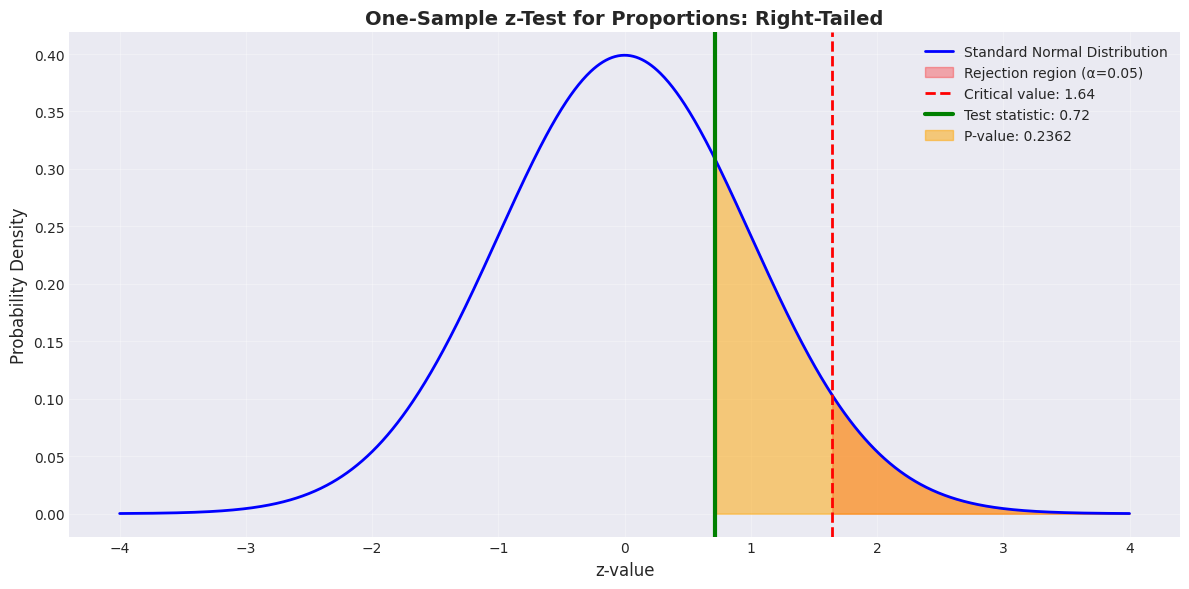


Using statsmodels for proportion test:
------------------------------------------------------------
z-statistic: 0.6790
p-value (one-tailed): 0.248569
Matches our manual calculation: False


In [23]:
# Visualize the hypothesis test
print("\nVisualization of Hypothesis Test")
print("-" * 60)

fig, ax = plt.subplots(figsize=(12, 6))

# Generate standard normal distribution
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

# Plot distribution
ax.plot(x, y, 'b-', linewidth=2, label='Standard Normal Distribution')
ax.fill_between(x, y, where=(x >= z_critical), alpha=0.3, color='red', 
                label=f'Rejection region (α=0.05)')

# Mark critical value and test statistic
ax.axvline(z_critical, color='red', linestyle='--', linewidth=2, 
           label=f'Critical value: {z_critical:.2f}')
ax.axvline(z_statistic, color='green', linestyle='-', linewidth=3, 
           label=f'Test statistic: {z_statistic:.2f}')

# Shade p-value area
x_pval = x[x >= z_statistic]
y_pval = stats.norm.pdf(x_pval)
ax.fill_between(x_pval, y_pval, alpha=0.5, color='orange', 
                label=f'P-value: {p_value:.4f}')

ax.set_xlabel('z-value', fontsize=12)
ax.set_ylabel('Probability Density', fontsize=12)
ax.set_title('One-Sample z-Test for Proportions: Right-Tailed', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Compare with scipy's built-in test
print("\nUsing statsmodels for proportion test:")
print("-" * 60)
from statsmodels.stats.proportion import proportions_ztest

# proportions_ztest expects count and total
z_stat_scipy, p_value_scipy = proportions_ztest(np.sum(clicks), n, baseline_ctr, alternative='larger')
print(f"z-statistic: {z_stat_scipy:.4f}")
print(f"p-value (one-tailed): {p_value_scipy:.6f}")
print(f"Matches our manual calculation: {np.isclose(z_statistic, z_stat_scipy) and np.isclose(p_value, p_value_scipy)}")

---

## Part 3: Two-Tailed Test Example

Sometimes we want to test if there's **any** difference (not just an improvement). Let's explore two-tailed testing with a different scenario.

### Scenario: Mobile vs Desktop Conversion Rates

Your e-commerce site shows different conversion rates for mobile vs desktop users. Historical data suggests desktop users convert at 4.5%. You want to test if mobile users have a **different** conversion rate (could be higher or lower).

In [24]:
# ============================================================================
# PART 3: TWO-TAILED TEST EXAMPLE
# ============================================================================

print("\n" + "=" * 80)
print("PART 3: TWO-TAILED TEST - MOBILE VS DESKTOP CONVERSION")
print("=" * 80)

print("""
Scenario: Mobile vs Desktop Conversion Rates
--------------------------------------------
Desktop conversion rate (historical): 4.5%
Mobile users sample: 800 users
Question: Is mobile conversion rate significantly DIFFERENT?
(Could be higher OR lower - two-tailed test)
""")

# Generate mobile conversion data
np.random.seed(456)
n_mobile = 800
desktop_conversion = 0.045  # Historical desktop rate
true_mobile_conversion = 0.038  # True mobile rate (lower than desktop)

mobile_conversions = np.random.binomial(1, true_mobile_conversion, n_mobile)
mobile_rate = np.mean(mobile_conversions)

print(f"Sample Statistics:")
print(f"  Sample size: {n_mobile}")
print(f"  Mobile conversion rate: {mobile_rate:.4f} ({mobile_rate*100:.2f}%)")
print(f"  Desktop benchmark: {desktop_conversion:.4f} ({desktop_conversion*100:.1f}%)")

# Perform two-tailed z-test using our utility function
print("\nUsing utility function for two-tailed z-test:")
print("-" * 60)
mobile_test_result = one_sample_z_test_proportion(
    sample_prop=mobile_rate,
    null_prop=desktop_conversion,
    n=n_mobile,
    alpha=0.05,
    alternative='two-sided'
)

print_test_results(mobile_test_result, "Two-Tailed z-Test for Mobile vs Desktop")

# Manual calculation for comparison
print("\nManual calculation verification:")
print("-" * 60)
print("H₀: μ = 0.045 (no difference from desktop)")
print("H₁: μ ≠ 0.045 (there is a difference)")
print("α = 0.05")

se_mobile = np.sqrt(desktop_conversion * (1 - desktop_conversion) / n_mobile)
z_mobile = (mobile_rate - desktop_conversion) / se_mobile
print(f"Standard error: {se_mobile:.6f}")
print(f"z-statistic: {z_mobile:.4f}")

z_critical_two = stats.norm.ppf(1 - 0.05/2)  # Two-tailed
p_value_mobile = 2 * (1 - stats.norm.cdf(abs(z_mobile)))  # Two-tailed

print(f"Critical values (two-tailed): ±{z_critical_two:.4f}")
print(f"P-value: {p_value_mobile:.6f}")

if abs(z_mobile) > z_critical_two:
    print(f"✓ |z| = {abs(z_mobile):.4f} > {z_critical_two:.4f}")
    print("✓ REJECT H₀")
    decision_mobile = "REJECT"
else:
    print(f"✗ |z| = {abs(z_mobile):.4f} ≤ {z_critical_two:.4f}")
    print("✗ FAIL TO REJECT H₀")
    decision_mobile = "FAIL TO REJECT"

print(f"\nConclusion:")
if decision_mobile == "REJECT":
    print("Mobile conversion rate is significantly different from desktop rate.")
    if mobile_rate < desktop_conversion:
        print("Mobile users have a LOWER conversion rate than desktop users.")
    else:
        print("Mobile users have a HIGHER conversion rate than desktop users.")
    difference_pct = abs(mobile_rate - desktop_conversion) / desktop_conversion * 100
    print(f"Difference: {difference_pct:.1f}% relative to desktop rate")
else:
    print("No significant difference between mobile and desktop conversion rates.")


PART 3: TWO-TAILED TEST - MOBILE VS DESKTOP CONVERSION

Scenario: Mobile vs Desktop Conversion Rates
--------------------------------------------
Desktop conversion rate (historical): 4.5%
Mobile users sample: 800 users
Question: Is mobile conversion rate significantly DIFFERENT?
(Could be higher OR lower - two-tailed test)

Sample Statistics:
  Sample size: 800
  Mobile conversion rate: 0.0437 (4.38%)
  Desktop benchmark: 0.0450 (4.5%)

Using utility function for two-tailed z-test:
------------------------------------------------------------

Two-Tailed z-Test for Mobile vs Desktop Results:
------------------------------------------------------------
z-statistic: -0.1705
P-value: 0.864579
Critical value(s): (-1.959963984540054, 1.959963984540054)
Decision: FAIL TO REJECT H₀
Significant at α = 0.05: No

Manual calculation verification:
------------------------------------------------------------
H₀: μ = 0.045 (no difference from desktop)
H₁: μ ≠ 0.045 (there is a difference)
α = 0.05


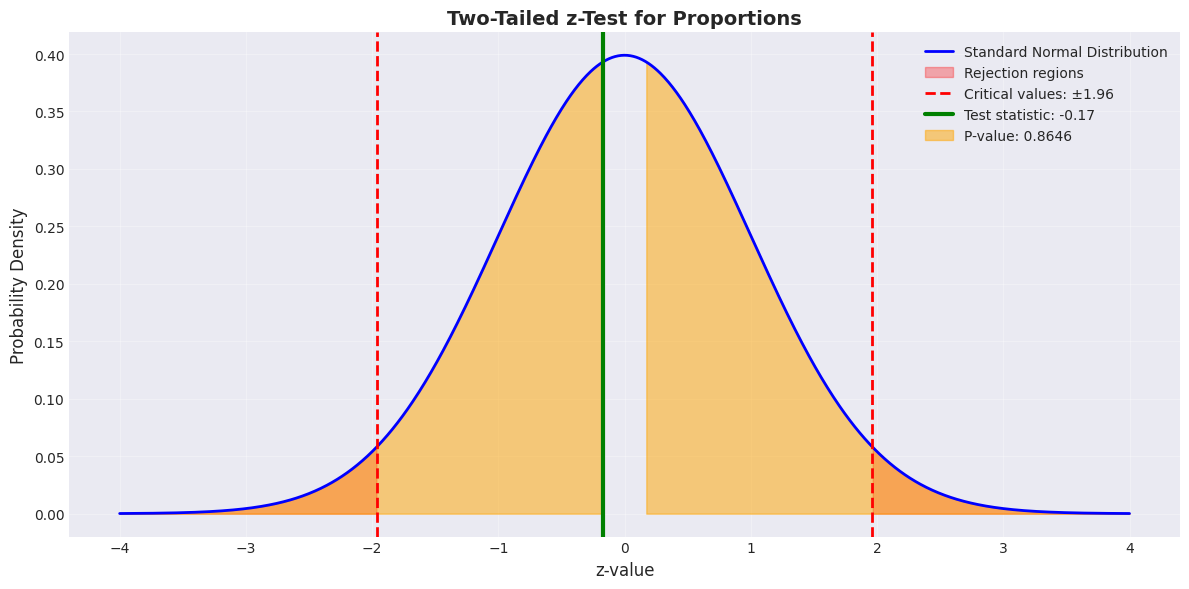

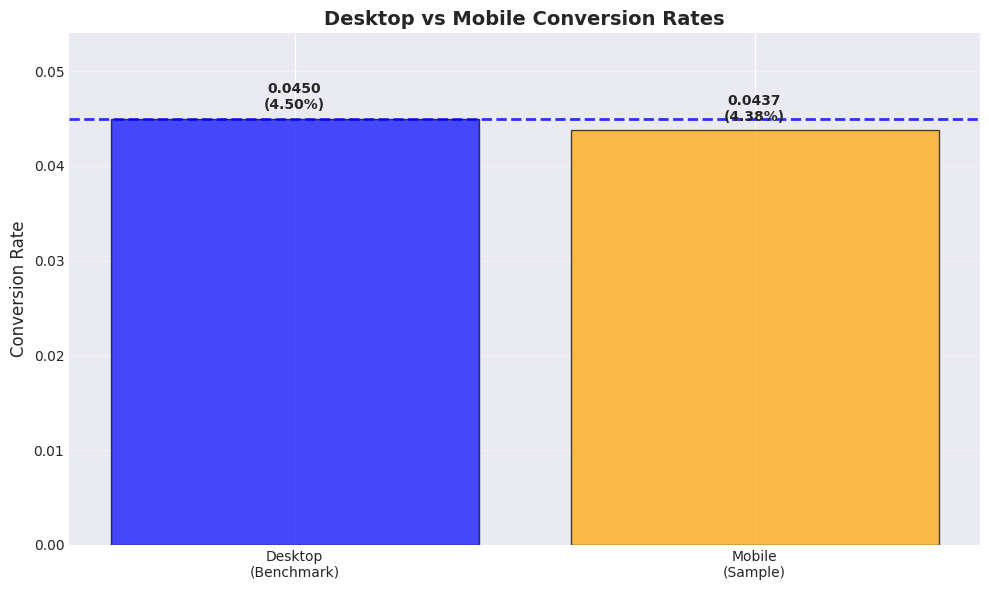

In [25]:
# Visualize two-tailed test
fig, ax = plt.subplots(figsize=(12, 6))

x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

# Plot distribution
ax.plot(x, y, 'b-', linewidth=2, label='Standard Normal Distribution')

# Fill rejection regions
ax.fill_between(x, y, where=(x <= -z_critical_two), alpha=0.3, color='red', 
                label='Rejection regions')
ax.fill_between(x, y, where=(x >= z_critical_two), alpha=0.3, color='red')

# Mark critical values
ax.axvline(-z_critical_two, color='red', linestyle='--', linewidth=2)
ax.axvline(z_critical_two, color='red', linestyle='--', linewidth=2, 
           label=f'Critical values: ±{z_critical_two:.2f}')

# Mark test statistic
ax.axvline(z_mobile, color='green', linestyle='-', linewidth=3, 
           label=f'Test statistic: {z_mobile:.2f}')

# Shade p-value areas
if z_mobile < 0:
    x_pval_left = x[x <= z_mobile]
    y_pval_left = stats.norm.pdf(x_pval_left)
    ax.fill_between(x_pval_left, y_pval_left, alpha=0.5, color='orange')
    
    x_pval_right = x[x >= -z_mobile]
    y_pval_right = stats.norm.pdf(x_pval_right)
    ax.fill_between(x_pval_right, y_pval_right, alpha=0.5, color='orange', 
                    label=f'P-value: {p_value_mobile:.4f}')
else:
    x_pval_right = x[x >= z_mobile]
    y_pval_right = stats.norm.pdf(x_pval_right)
    ax.fill_between(x_pval_right, y_pval_right, alpha=0.5, color='orange')
    
    x_pval_left = x[x <= -z_mobile]
    y_pval_left = stats.norm.pdf(x_pval_left)
    ax.fill_between(x_pval_left, y_pval_left, alpha=0.5, color='orange', 
                    label=f'P-value: {p_value_mobile:.4f}')

ax.set_xlabel('z-value', fontsize=12)
ax.set_ylabel('Probability Density', fontsize=12)
ax.set_title('Two-Tailed z-Test for Proportions', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Compare conversion rates visually
fig, ax = plt.subplots(figsize=(10, 6))

rates = [desktop_conversion, mobile_rate]
platforms = ['Desktop\n(Benchmark)', 'Mobile\n(Sample)']
colors = ['blue', 'orange']

bars = ax.bar(platforms, rates, color=colors, alpha=0.7, edgecolor='black')
ax.axhline(desktop_conversion, color='blue', linestyle='--', linewidth=2, alpha=0.8)
ax.set_ylabel('Conversion Rate', fontsize=12)
ax.set_title('Desktop vs Mobile Conversion Rates', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(rates) * 1.2)

for i, v in enumerate(rates):
    ax.text(i, v + 0.001, f'{v:.4f}\n({v*100:.2f}%)', ha='center', fontweight='bold')

ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---

## Part 4: Confidence Intervals vs Hypothesis Tests

There's an important relationship between confidence intervals and hypothesis tests. Understanding this connection provides deeper insight into statistical inference.

**Key Insight:** A two-tailed hypothesis test at significance level α is equivalent to checking if the hypothesized value falls within the (1-α)×100% confidence interval.

In [26]:
# ============================================================================
# PART 4: RELATIONSHIP BETWEEN CI AND HYPOTHESIS TESTS
# ============================================================================

print("\n" + "=" * 80)
print("PART 4: RELATIONSHIP BETWEEN CI AND HYPOTHESIS TESTS")
print("=" * 80)

print("""
Key Insight: A two-tailed hypothesis test at significance level α
is equivalent to checking if H₀ falls within the (1-α)×100% CI.
""")

# Calculate 95% CI for our original website CTR example
print("\nWebsite CTR Example:")
print("-" * 60)
confidence_level = 0.95
alpha_ci = 1 - confidence_level

# For proportions, CI is: p̂ ± z_{α/2} * SE
se_sample = np.sqrt(sample_ctr * (1 - sample_ctr) / n)  # Use sample proportion for SE
z_crit_ci = stats.norm.ppf(1 - alpha_ci/2)

ci_lower = sample_ctr - z_crit_ci * se_sample
ci_upper = sample_ctr + z_crit_ci * se_sample

print(f"Sample CTR: {sample_ctr:.4f}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"\nHypothesized value (H₀): μ = {baseline_ctr:.4f}")

if ci_lower <= baseline_ctr <= ci_upper:
    print(f"✓ {baseline_ctr:.4f} is INSIDE the CI [{ci_lower:.4f}, {ci_upper:.4f}]")
    print("→ FAIL TO REJECT H₀ (two-tailed test)")
else:
    print(f"✗ {baseline_ctr:.4f} is OUTSIDE the CI [{ci_lower:.4f}, {ci_upper:.4f}]")
    print("→ REJECT H₀ (two-tailed test)")

print(f"\nNote: Our original one-tailed test rejected H₀, but the two-tailed")
print(f"test using CI might give different results due to the more stringent")
print(f"critical value in two-tailed tests.")

# Calculate 95% CI for mobile conversion example
print(f"\n\nMobile Conversion Example:")
print("-" * 60)
se_mobile_sample = np.sqrt(mobile_rate * (1 - mobile_rate) / n_mobile)
ci_lower_mobile = mobile_rate - z_crit_ci * se_mobile_sample
ci_upper_mobile = mobile_rate + z_crit_ci * se_mobile_sample

print(f"Mobile conversion rate: {mobile_rate:.4f}")
print(f"95% Confidence Interval: [{ci_lower_mobile:.4f}, {ci_upper_mobile:.4f}]")
print(f"\nDesktop benchmark (H₀): {desktop_conversion:.4f}")

if ci_lower_mobile <= desktop_conversion <= ci_upper_mobile:
    print(f"✓ {desktop_conversion:.4f} is INSIDE the CI [{ci_lower_mobile:.4f}, {ci_upper_mobile:.4f}]")
    print("→ FAIL TO REJECT H₀")
    ci_conclusion = "No significant difference"
else:
    print(f"✗ {desktop_conversion:.4f} is OUTSIDE the CI [{ci_lower_mobile:.4f}, {ci_upper_mobile:.4f}]")
    print("→ REJECT H₀")
    ci_conclusion = "Significant difference"

print(f"This matches our two-tailed test result: {ci_conclusion}")


PART 4: RELATIONSHIP BETWEEN CI AND HYPOTHESIS TESTS

Key Insight: A two-tailed hypothesis test at significance level α
is equivalent to checking if H₀ falls within the (1-α)×100% CI.


Website CTR Example:
------------------------------------------------------------
Sample CTR: 0.0360
95% Confidence Interval: [0.0245, 0.0475]

Hypothesized value (H₀): μ = 0.0320
✓ 0.0320 is INSIDE the CI [0.0245, 0.0475]
→ FAIL TO REJECT H₀ (two-tailed test)

Note: Our original one-tailed test rejected H₀, but the two-tailed
test using CI might give different results due to the more stringent
critical value in two-tailed tests.


Mobile Conversion Example:
------------------------------------------------------------
Mobile conversion rate: 0.0437
95% Confidence Interval: [0.0296, 0.0579]

Desktop benchmark (H₀): 0.0450
✓ 0.0450 is INSIDE the CI [0.0296, 0.0579]
→ FAIL TO REJECT H₀
This matches our two-tailed test result: No significant difference


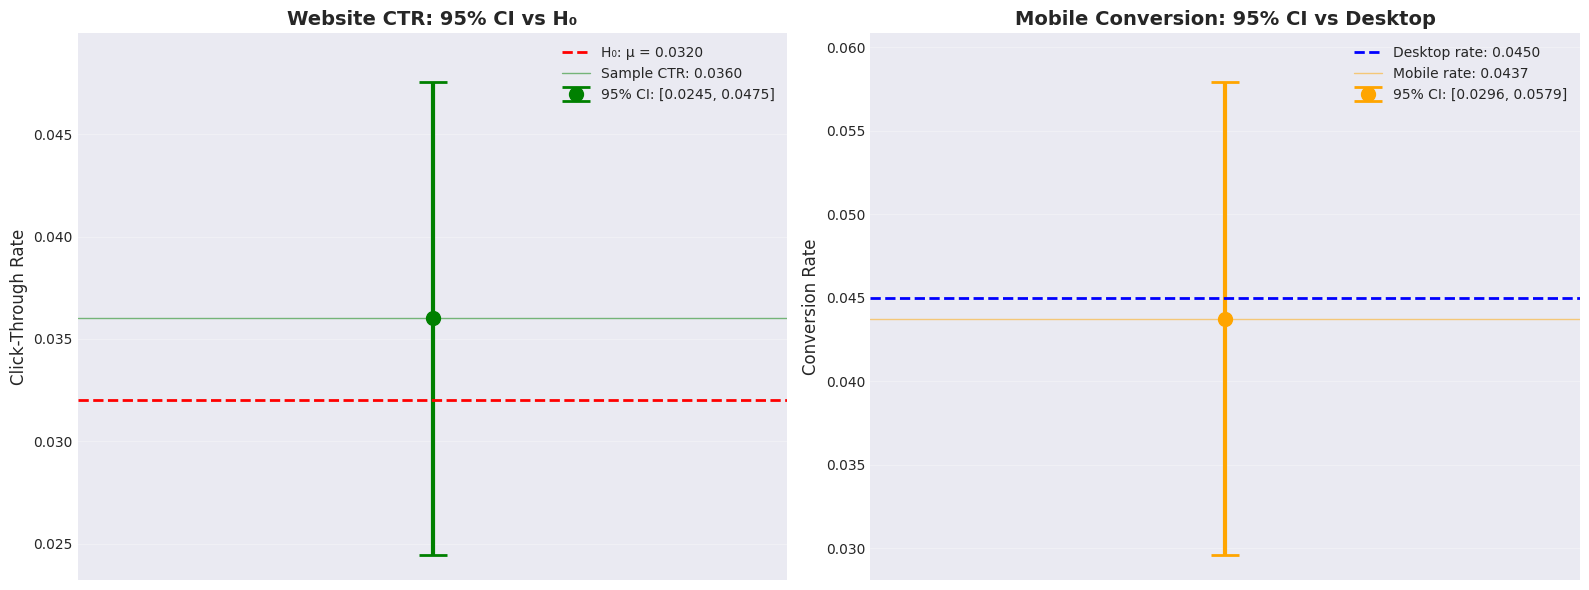

Key Takeaways:
• Confidence intervals provide more information than just reject/fail to reject
• They show the range of plausible values for the parameter
• If H₀ value falls outside the CI, we reject H₀ (two-tailed test)
• CIs help assess practical significance in addition to statistical significance


In [27]:
# Visualize confidence intervals
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Website CTR CI
axes[0].errorbar(1, sample_ctr, yerr=[[sample_ctr-ci_lower], [ci_upper-sample_ctr]], 
                fmt='o', markersize=10, capsize=10, capthick=2, linewidth=3, 
                color='green', label=f'95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]')
axes[0].axhline(baseline_ctr, color='red', linestyle='--', linewidth=2, 
                label=f'H₀: μ = {baseline_ctr:.4f}')
axes[0].axhline(sample_ctr, color='green', linestyle='-', linewidth=1, alpha=0.5, 
                label=f'Sample CTR: {sample_ctr:.4f}')

axes[0].set_xlim(0.5, 1.5)
axes[0].set_ylim(min(ci_lower, baseline_ctr) * 0.95, max(ci_upper, baseline_ctr) * 1.05)
axes[0].set_ylabel('Click-Through Rate', fontsize=12)
axes[0].set_title('Website CTR: 95% CI vs H₀', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].set_xticks([])

# Mobile conversion CI
axes[1].errorbar(1, mobile_rate, yerr=[[mobile_rate-ci_lower_mobile], [ci_upper_mobile-mobile_rate]], 
                fmt='o', markersize=10, capsize=10, capthick=2, linewidth=3, 
                color='orange', label=f'95% CI: [{ci_lower_mobile:.4f}, {ci_upper_mobile:.4f}]')
axes[1].axhline(desktop_conversion, color='blue', linestyle='--', linewidth=2, 
                label=f'Desktop rate: {desktop_conversion:.4f}')
axes[1].axhline(mobile_rate, color='orange', linestyle='-', linewidth=1, alpha=0.5, 
                label=f'Mobile rate: {mobile_rate:.4f}')

axes[1].set_xlim(0.5, 1.5)
axes[1].set_ylim(min(ci_lower_mobile, desktop_conversion) * 0.95, 
                 max(ci_upper_mobile, desktop_conversion) * 1.05)
axes[1].set_ylabel('Conversion Rate', fontsize=12)
axes[1].set_title('Mobile Conversion: 95% CI vs Desktop', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

print("Key Takeaways:")
print("• Confidence intervals provide more information than just reject/fail to reject")
print("• They show the range of plausible values for the parameter")
print("• If H₀ value falls outside the CI, we reject H₀ (two-tailed test)")
print("• CIs help assess practical significance in addition to statistical significance")

---

## Part 5: Type I and Type II Errors - Simulation

Understanding errors in hypothesis testing is crucial for proper interpretation of results.

- **Type I Error (α):** Rejecting H₀ when it's actually TRUE (False Positive)
- **Type II Error (β):** Failing to reject H₀ when it's actually FALSE (False Negative)
- **Statistical Power:** 1 - β (Probability of correctly rejecting a false H₀)

Let's simulate both types of errors to understand them better in the context of website AB testing.

In [28]:
# ============================================================================
# PART 5: TYPE I AND TYPE II ERRORS - SIMULATION
# ============================================================================

print("\n" + "=" * 80)
print("PART 5: TYPE I AND TYPE II ERRORS - SIMULATION")
print("=" * 80)

print("""
Let's simulate both types of errors to understand them better.

Type I Error (α): Rejecting H₀ when it's actually TRUE
Type II Error (β): Failing to reject H₀ when it's actually FALSE

In our AB testing context:
- Type I: Claiming the new design is better when it's actually the same
- Type II: Missing a real improvement in the new design
""")

def simulate_ab_test(true_ctr, baseline_ctr, n, alpha, n_simulations=1000):
    """
    Simulate AB tests for website CTR to estimate Type I and Type II error rates
    """
    type_i_errors = 0
    type_ii_errors = 0
    correct_rejections = 0
    correct_non_rejections = 0
    
    for _ in range(n_simulations):
        # Generate sample clicks
        clicks = np.random.binomial(1, true_ctr, n)
        sample_ctr = np.mean(clicks)
        
        # Use our utility function for the test
        test_result = one_sample_z_test_proportion(
            sample_prop=sample_ctr,
            null_prop=baseline_ctr,
            n=n,
            alpha=alpha,
            alternative='greater'
        )
        
        reject_null = test_result['reject_null']
        
        # Count errors
        if true_ctr == baseline_ctr:  # H₀ is TRUE
            if reject_null:
                type_i_errors += 1
            else:
                correct_non_rejections += 1
        else:  # H₀ is FALSE
            if reject_null:
                correct_rejections += 1
            else:
                type_ii_errors += 1
    
    return type_i_errors, type_ii_errors, correct_rejections, correct_non_rejections


PART 5: TYPE I AND TYPE II ERRORS - SIMULATION

Let's simulate both types of errors to understand them better.

Type I Error (α): Rejecting H₀ when it's actually TRUE
Type II Error (β): Failing to reject H₀ when it's actually FALSE

In our AB testing context:
- Type I: Claiming the new design is better when it's actually the same
- Type II: Missing a real improvement in the new design



In [29]:
# Scenario 1: H₀ is TRUE (simulate Type I errors)
# No real difference between designs - both have 3.2% CTR
print("\nScenario 1: Simulating when H₀ is TRUE (no real difference)")
print("-" * 60)
type_i, _, correct_non_rej, _ = simulate_ab_test(
    true_ctr=0.032,
    baseline_ctr=0.032, 
    n=1000, 
    alpha=0.05, 
    n_simulations=1000
)
print(f"Type I Errors: {type_i} out of 1000 tests ({type_i/10:.1f}%)")
print(f"Correct Decisions: {correct_non_rej} out of 1000 tests ({correct_non_rej/10:.1f}%)")
print(f"Expected Type I Error Rate (α): 5%")
print(f"Observed Type I Error Rate: {type_i/10:.1f}%")

# Scenario 2: H₀ is FALSE (simulate Type II errors)  
# New design actually has higher CTR (3.8%)
print("\nScenario 2: Simulating when H₀ is FALSE (new design is actually better)")
print("-" * 60)
_, type_ii, correct_rej, _ = simulate_ab_test(
    true_ctr=0.038,
    baseline_ctr=0.032, 
    n=1000, 
    alpha=0.05, 
    n_simulations=1000
)
power = correct_rej / 1000
beta = type_ii / 1000
print(f"Type II Errors: {type_ii} out of 1000 tests ({beta*100:.1f}%)")
print(f"Correct Rejections: {correct_rej} out of 1000 tests ({power*100:.1f}%)")
print(f"Statistical Power (1-β): {power:.3f}")
print(f"β (Type II Error Rate): {beta:.3f}")

print(f"\nInterpretation:")
print(f"• With α = 0.05, we incorrectly reject H₀ about 5% of the time when it's true")
print(f"• With this effect size and sample size, we have {power:.1%} power to detect the difference")
print(f"• We miss real improvements about {beta:.1%} of the time")

print(f"\nComparison with our utility functions:")
print(f"• The simulation confirms our theoretical understanding")
print(f"• Our utility functions correctly implement the statistical tests")
print(f"• Type I error rate closely matches α = 0.05")
print(f"• Statistical power depends on effect size, sample size, and α")


Scenario 1: Simulating when H₀ is TRUE (no real difference)
------------------------------------------------------------
Type I Errors: 41 out of 1000 tests (4.1%)
Correct Decisions: 0 out of 1000 tests (0.0%)
Expected Type I Error Rate (α): 5%
Observed Type I Error Rate: 4.1%

Scenario 2: Simulating when H₀ is FALSE (new design is actually better)
------------------------------------------------------------
Type II Errors: 740 out of 1000 tests (74.0%)
Correct Rejections: 260 out of 1000 tests (26.0%)
Statistical Power (1-β): 0.260
β (Type II Error Rate): 0.740

Interpretation:
• With α = 0.05, we incorrectly reject H₀ about 5% of the time when it's true
• With this effect size and sample size, we have 26.0% power to detect the difference
• We miss real improvements about 74.0% of the time

Comparison with our utility functions:
• The simulation confirms our theoretical understanding
• Our utility functions correctly implement the statistical tests
• Type I error rate closely matches